In [1]:
import pandas as pd
import numpy as np
import sys
import glob
import seaborn as sns
import matplotlib.pyplot as plt


import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'  # Keep text as text (not paths)

In [2]:
files = glob.glob(f"/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/09.subsampling_analysis/*.csv")

df = pd.DataFrame()
for file in files:
    df_tmp = pd.read_csv(file, header = 0)
    df_tmp['n_train'] = int(file.split("/")[-1].split(".")[-2])
    df = pd.concat([df, df_tmp], ignore_index=True)


df

,original_CpG,train_num,total_CpG,selected_CpG,cv_auc,best_c,best_l1_ratio,Test_Accuracy,Test_Balanced_Accuracy,Test_Brier_Score,n_train
0,562447,40,9501,532,1.0,100,0.75,1.0,1.0,0.000015,40
1,562447,20,7892,69,1.0,100,0.75,1.0,1.0,0.000060,20
2,562447,70,10069,10069,1.0,1000,0.00,1.0,1.0,0.000035,70
3,562447,60,9652,569,1.0,100,1.00,1.0,1.0,0.000010,60
4,562447,80,10260,8150,1.0,1000,1.00,1.0,1.0,0.000025,80
5,562447,15,9709,69,1.0,100,0.50,1.0,1.0,0.000068,15
6,562447,25,8005,76,1.0,100,0.75,1.0,1.0,0.000056,25
7,562447,50,9391,825,1.0,100,0.75,1.0,1.0,0.000010,50
8,562447,10,8982,65,1.0,100,0.50,1.0,1.0,0.000088,10
9,562447,30,8674,151,1.0,100,0.75,1.0,1.0,0.000066,30


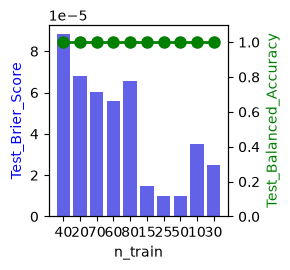

In [3]:
y1 = "Test_Brier_Score"
y2 = "Test_Balanced_Accuracy"

fig, ax1 = plt.subplots(figsize = (3, 2.8))

# First y-axis (left): Test_Brier_Score
ax1.set_xlabel("n_train")
ax1.set_ylabel(y1, color = "blue")
sns.barplot(data = df, x = "n_train", y = y1, color = "blue", alpha = 0.7, ax = ax1)
ax1.tick_params(axis = 'y', labelcolor = "black")

# Second y-axis (right): Test_Balanced_Accuracy
ax2 = ax1.twinx()
ax2.set_ylabel(y2, color = "green")
# Use numeric indices for lineplot to work properly with categorical x-axis
ax2.plot(range(len(df)), df[y2], color = "green", marker = "o", linewidth = 2, markersize = 8, label = y2)
ax2.set_xticks(range(len(df)))
ax2.set_ylim(0,1.1)
ax2.set_xticklabels(df["n_train"])
ax2.tick_params(axis = 'y', labelcolor = "black")


plt.tight_layout()
plt.savefig(f"/home/jhu/jkim789/projects_aphill27/projects/pooch/figures/figure6/subsampling.pdf")
plt.show()

## Prediction

In [15]:
import pandas as pd
import glob
import re

results = []

for file in glob.glob("/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/07.models_selection_using_fdr_balance_X_n46_xist_slope_adjust/hg002/resource_usage.chr*.log"):

    with open(file) as f:
        text = f.read()

    def extract(pattern):
        match = re.search(pattern, text)
        return float(match.group(1)) if match else None

    # Chromosome
    chr_match = re.search(r'Command being timed: "sh predict.sh (chr\w+)"', text)
    chrom = chr_match.group(1) if chr_match else None

    # CPU time
    user_time = extract(r"User time \(seconds\):\s*([\d.]+)")
    system_time = extract(r"System time \(seconds\):\s*([\d.]+)")

    # Wall-clock time
    wall_match = re.search(
        r"Elapsed \(wall clock\) time \(h:mm:ss or m:ss\):\s*(\S+)",
        text
    )

    wall_time = None
    if wall_match:
        parts = list(map(float, wall_match.group(1).split(":")))
        wall_time = sum(
            value * 60**i
            for i, value in enumerate(reversed(parts))
        )

    # Peak memory
    memory_kb = extract(r"Maximum resident set size \(kbytes\):\s*(\d+)")

    # CPU utilization
    cpu_percent = extract(r"Percent of CPU this job got:\s*([\d.]+)%")

    results.append({
        "chr": chrom,
        "wall_time_sec": wall_time,
        "cpu_time_sec": (
            user_time + system_time
            if user_time is not None and system_time is not None
            else None
        ),
        "cpu_percent": cpu_percent,
        "peak_memory_GiB": memory_kb / 1024**2 if memory_kb is not None else None,
        "exit_status": extract(r"Exit status:\s*(\d+)")
    })

benchmark_df = pd.DataFrame(results)

# Sort chromosomes numerically
chr_order = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]

benchmark_df["chr"] = pd.Categorical(
    benchmark_df["chr"],
    categories=chr_order,
    ordered=True
)

benchmark_df = benchmark_df.sort_values("chr").reset_index(drop=True)
benchmark_df['sample'] = ""
print(benchmark_df)

      chr  wall_time_sec  cpu_time_sec  cpu_percent  peak_memory_GiB  \
0    chr1          36.35         48.99        134.0         0.547039   
1    chr2          35.33         47.99        135.0         0.529362   
2    chr3          21.22         33.34        157.0         0.446289   
3    chr4          19.77         31.68        160.0         0.432278   
4    chr5          19.94         31.88        159.0         0.430691   
5    chr6          20.77         32.76        157.0         0.431671   
6    chr7          24.16         36.22        149.0         0.448097   
7    chr8          25.42         35.96        141.0         0.431137   
8    chr9          16.14         27.14        168.0         0.388565   
9   chr10          18.42         29.45        159.0         0.412392   
10  chr11          21.61         33.31        154.0         0.421421   
11  chr12          16.77         28.04        167.0         0.397362   
12  chr13          12.71         23.30        183.0         0.33

In [16]:
benchmark_df.describe()

,wall_time_sec,cpu_time_sec,cpu_percent,peak_memory_GiB,exit_status
count,23.000000,23.00000,23.000000,23.000000,23.0
mean,18.528261,29.64913,168.739130,0.403018,0.0
std,7.703330,8.78924,26.091129,0.069797,0.0
min,4.920000,12.28000,134.000000,0.271873,0.0
25%,14.230000,25.46500,155.500000,0.357565,0.0
50%,18.420000,29.45000,162.000000,0.397362,0.0
75%,21.415000,33.32500,179.000000,0.431974,0.0
max,36.350000,48.99000,249.000000,0.547039,0.0


In [22]:
benchmark_df.to_csv("/home/jhu/jkim789/projects_aphill27/projects/pooch/pooch_data/07.models_selection_using_fdr_balance_X_n46_xist_slope_adjust/hg002/benchmark.tsv",sep = '\t', header = True, )

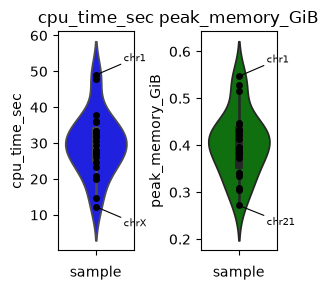

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

y1 = "cpu_time_sec"
y2 = "peak_memory_GiB"

fig, axes = plt.subplots(1, 2, figsize=(3, 3))

sample_order = benchmark_df["sample"].dropna().unique().tolist()

for ax, y, color in zip(
    axes,
    [y1, y2],
    ["blue", "green"]
):
    sns.violinplot(
        data=benchmark_df,
        x="sample",
        y=y,
        order=sample_order,
        color=color,
        ax=ax
    )

    sns.stripplot(
        data=benchmark_df,
        x="sample",
        y=y,
        order=sample_order,
        color="black",
        size=5,
        jitter=False,
        ax=ax
    )

    # Find minimum and maximum points
    idx_min = benchmark_df[y].idxmin()
    idx_max = benchmark_df[y].idxmax()

    for idx in {idx_min, idx_max}:
        row = benchmark_df.loc[idx]

        x_pos = sample_order.index(row["sample"])
        y_pos = row[y]

        is_max = idx == idx_max

        ax.annotate(
            str(row["chr"]),
            xy=(x_pos, y_pos),
            xytext=(20, 12 if is_max else -12),
            textcoords="offset points",
            fontsize=7,
            ha="left",
            va="center",
            arrowprops=dict(
                arrowstyle="-",
                color="black",
                lw=0.8,
                shrinkA=0,
                shrinkB=0,
                connectionstyle="arc3,rad=0"
            ),
            annotation_clip=False,
            zorder=10
        )

    ax.set_title(y)
    ax.tick_params(axis="x", rotation=90)

plt.tight_layout()

plt.savefig(
    f"/home/jhu/jkim789/projects_aphill27/projects/pooch/figures/figure6/prediction_{y1}_{y2}.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()